In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# dane-data frente a las cifras del DANE

¿Coinciden los indicadores de `dane-data` con los que publica el DANE? Este ejemplo compara cada mes desde
2007 con los anexos oficiales del mercado laboral, que el repositorio guarda en
`tests/datos/dane_publicado.csv` (vea {doc}`../guia/validacion`).

In [2]:
import dane_data as dd

publicado = pd.read_csv("../../tests/datos/dane_publicado.csv", comment="#")
publicado = publicado[(publicado.serie == "principal") & (publicado.grupo == "total")]
publicado[["anio", "mes", "td", "tgp", "to", "ocupados", "anexo"]].tail(3)

,anio,mes,td,tgp,to,ocupados,anexo
233,2026,6,8.026926,64.543037,59.362215,24458.794302,ago2026
234,2026,7,8.104578,64.768526,59.519311,24546.881455,ago2026
235,2026,8,9.363680,63.289540,57.363310,23685.337691,ago2026


In [3]:
nuestro = dd.geih.serie_indicadores(range(2007, 2027), anual=False)
comp = nuestro.merge(publicado, on=["anio", "mes"], suffixes=("", "_dane"))
comp["fecha"] = pd.to_datetime(comp[["anio", "mes"]].rename(columns={"anio": "year", "mes": "month"}).assign(day=1))
for tasa in ("td", "tgp", "to"):
    comp[f"dif_{tasa}"] = comp[tasa] - comp[f"{tasa}_dane"]
comp["dif_ocupados_%"] = 100 * (comp["ocupados"] / (1000 * comp["ocupados_dane"]) - 1)
comp[["dif_td", "dif_tgp", "dif_to", "dif_ocupados_%"]].abs().max()

dif_td            0.000049
dif_tgp           0.000047
dif_to            0.000042
dif_ocupados_%    0.000003
dtype: float64

En los 236 meses, la diferencia más grande en las tasas es de menos de una diezmilésima de punto, y en los
ocupados de menos de una millonésima: es el redondeo de los anexos, que traen seis decimales. Las cifras son
las mismas.

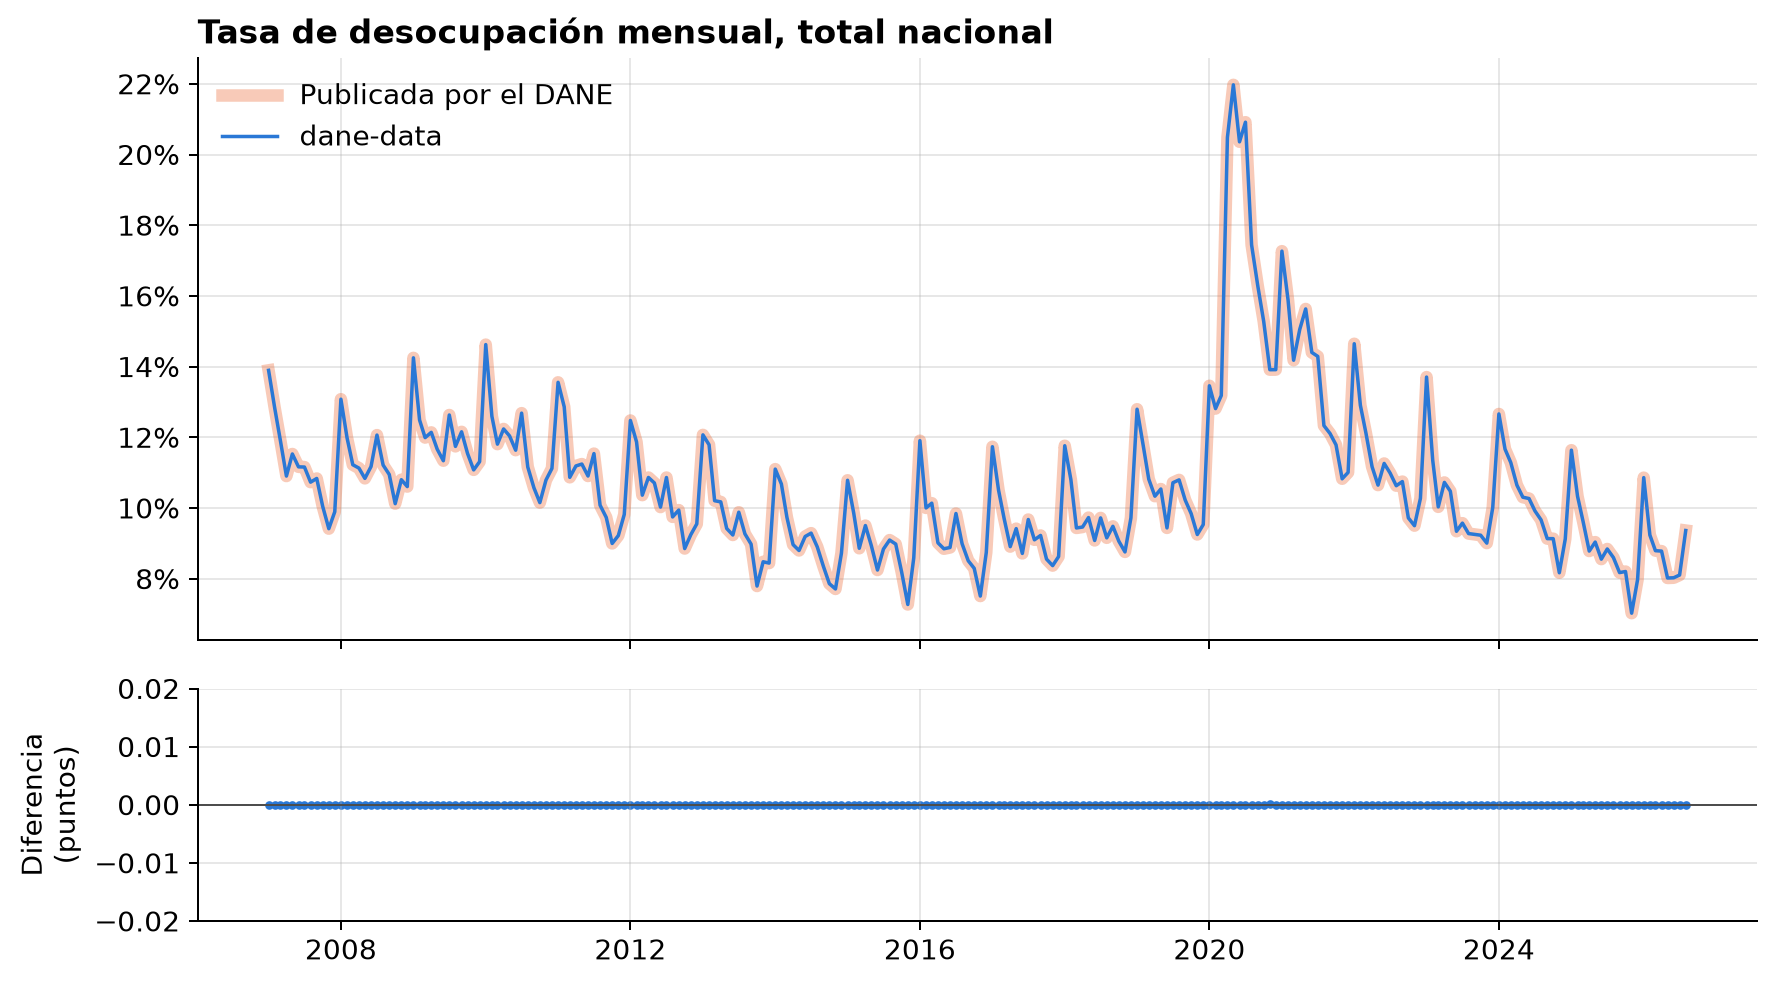

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
ax1.plot(comp["fecha"], comp["td_dane"], lw=5, color="#eb6834", alpha=0.35, label="Publicada por el DANE")
ax1.plot(comp["fecha"], comp["td"], lw=1.4, color="#2a78d6", label="dane-data")
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax1.set_title("Tasa de desocupación mensual, total nacional")
ax1.legend(loc="upper left")
ax2.scatter(comp["fecha"], comp["dif_td"], s=6, color="#2a78d6")
ax2.axhline(0, color="0.3", lw=0.8)
ax2.set_ylim(-0.02, 0.02)
ax2.set_ylabel("Diferencia\n(puntos)")
fig.tight_layout();

Las pruebas automáticas de `dane-data` hacen esta misma comparación para la TD, la TGP, la TO y los
ocupados, también en la serie de empalme, en las cabeceras y por sexo.